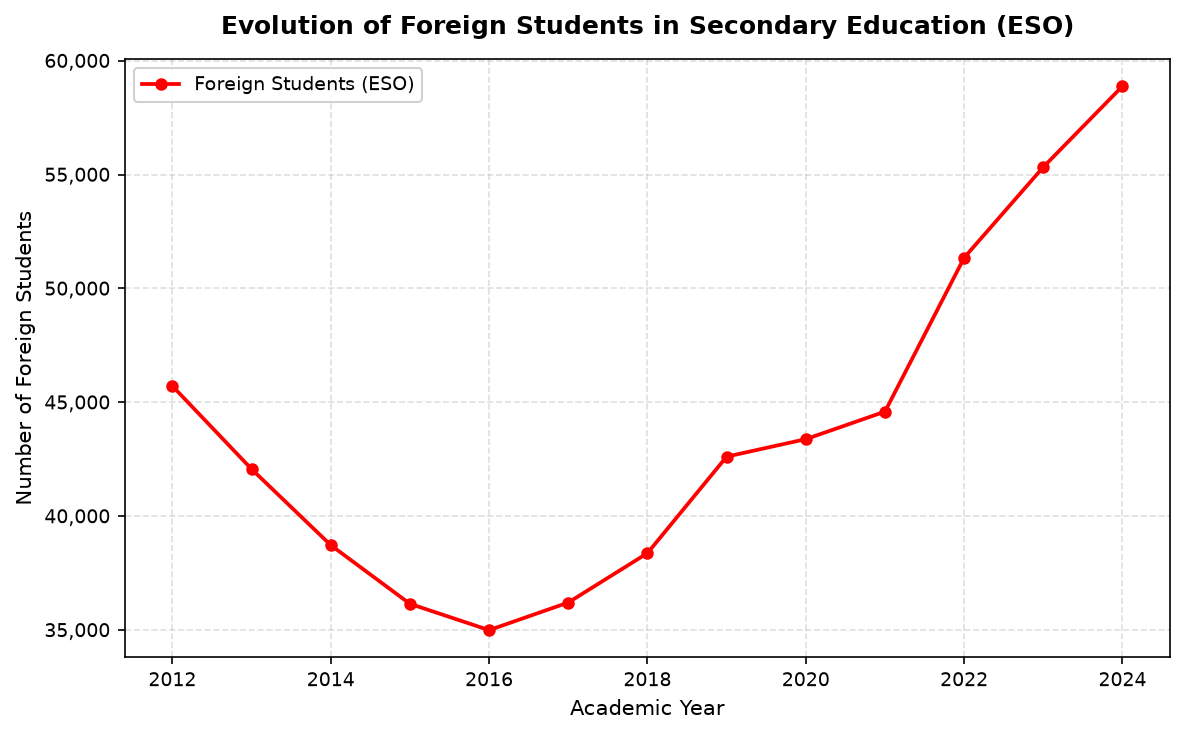

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import ticker

ROOT_DIR = Path.cwd().resolve().parents[1]

# 1. Llegim el CSV indicant thousands="." perquè no es mengi els zeros finals del 2020 i 2023
ruta_csv = ROOT_DIR / "data" / "processed" / "education" / "dades_netes_estrangers_eso.csv"
df_estrangers = pd.read_csv(ruta_csv, sep=None, engine="python", thousands=".")

anys = pd.to_numeric(df_estrangers.iloc[:, 0], errors="coerce")
alumnes = pd.to_numeric(df_estrangers.iloc[:, 1], errors="coerce")

# 2. Configuració del gràfic amb el mateix estil
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

ax.plot(
    anys,
    alumnes,
    color="red",
    marker="o",
    markersize=5,
    linewidth=1.8,
    label="Foreign Students (ESO)"
)

# 3. Títols i etiquetes en anglès
ax.set_title("Evolution of Foreign Students in Secondary Education (ESO)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Academic Year", fontsize=10)
ax.set_ylabel("Number of Foreign Students", fontsize=10)

# 4. Estil de la graella i format dels eixos
ax.grid(True, linestyle="--", alpha=0.4)
ax.set_xticks([2012, 2014, 2016, 2018, 2020, 2022, 2024])
ax.tick_params(axis="both", labelsize=9)
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

ax.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9, fontsize=9)

plt.tight_layout()
ruta_figura = ROOT_DIR / "results" / "figures" / "foreign_students_evolution.png"
ruta_figura.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(ruta_figura, dpi=300, bbox_inches="tight")
plt.show()